<a href="https://colab.research.google.com/github/code-ajay-17/Website-Traffic-Forecasting/blob/main/Website_Traffic_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

%pip install -q tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 778.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 81.8 MB/s eta 0:00:00


In [3]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)


/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


TensorFlow version: 2.21.0


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

print("All imports successful!")


All imports successful!


In [5]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

df = pd.read_csv("/content/validation_score.csv")
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
features = ["median7", "median14", "median21", "median28", "median35"]
df = df[features].apply(pd.to_numeric, errors="coerce")
df = df.replace([np.inf, -np.inf], np.nan)
df = df.ffill().bfill().fillna(0)
data = df.values
split = int(len(data) * 0.8)

scaler = MinMaxScaler()
scaler.fit(data[:split])
scaled_data = scaler.transform(data)

print("Dataset shape:", df.shape)
print("Training rows:", split)
print("Testing rows:", len(data) - split)

Dataset shape: (119673, 5)
Training rows: 95738
Testing rows: 23935


In [8]:
LOOKBACK = 30
X, y, target_indices = [], [], []

for i in range(LOOKBACK, len(scaled_data)):
    X.append(scaled_data[i-LOOKBACK:i])
    y.append(scaled_data[i])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

X_train, y_train = X[target_indices < split], y[target_indices < split]
X_test, y_test = X[target_indices >= split], y[target_indices >= split]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (95708, 30, 5)
X_test: (23935, 30, 5)


In [9]:
model = Sequential([
    tf.keras.Input(shape=(LOOKBACK, len(features))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(len(features))
])

model.compile(optimizer="adam", loss="mse")

history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

print("LSTM training completed!")

Epoch 1/10
2692/2692 ━━━━━━━━━━━━━━━━━━━━ 33s 12ms/step - loss: 0.0249 - val_loss: 0.0251
Epoch 2/10
2692/2692 ━━━━━━━━━━━━━━━━━━━━ 32s 12ms/step - loss: 0.0242 - val_loss: 0.0249
Epoch 3/10
2692/2692 ━━━━━━━━━━━━━━━━━━━━ 31s 11ms/step - loss: 0.0240 - val_loss: 0.0247
Epoch 4/10
2692/2692 ━━━━━━━━━━━━━━━━━━━━ 31s 12ms/step - loss: 0.0239 - val_loss: 0.0246
Epoch 5/10
2692/2692 ━━━━━━━━━━━━━━━━━━━━ 31s 12ms/step - loss: 0.0238 - val_loss: 0.0246
Epoch 6/10
2692/2692 ━━━━━━━━━━━━━━━━━━━━ 31s 12ms/step - loss: 0.0238 - val_loss: 0.0245
Epoch 7/10
2692/2692 ━━━━━━━━━━━━━━━━━━━━ 31s 12ms/step - loss: 0.0237 - val_loss: 0.0245
Epoch 8/10
2692/2692 ━━━━━━━━━━━━━━━━━━━━ 31s 12ms/step - loss: 0.0237 - val_loss: 0.0246
Epoch 9/10
2692/2692 ━━━━━━━━━━━━━━━━━━━━ 31s 11ms/step - loss: 0.0237 - val_loss: 0.0246
Epoch 10/10
2692/2692 ━━━━━━━━━━━━━━━━━━━━ 30s 11ms/step - loss: 0.0237 - val_loss: 0.0247
LSTM training completed!


In [10]:
predictions = model.predict(X_test, verbose=0)

actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(predictions)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

MAE: 0.2081
RMSE: 0.286


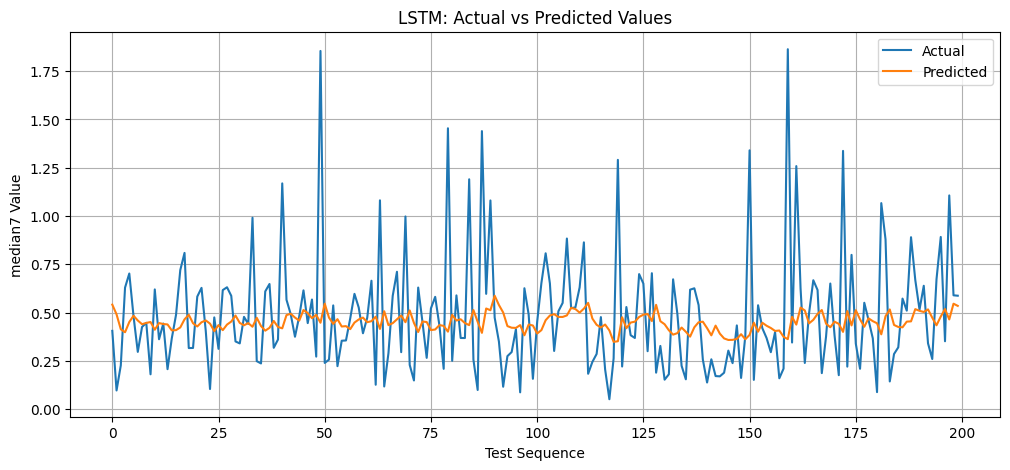

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(actual[:200, 0], label="Actual")
plt.plot(predicted[:200, 0], label="Predicted")

plt.title("LSTM: Actual vs Predicted Values")
plt.xlabel("Test Sequence")
plt.ylabel("median7 Value")
plt.legend()
plt.grid(True)
plt.show()

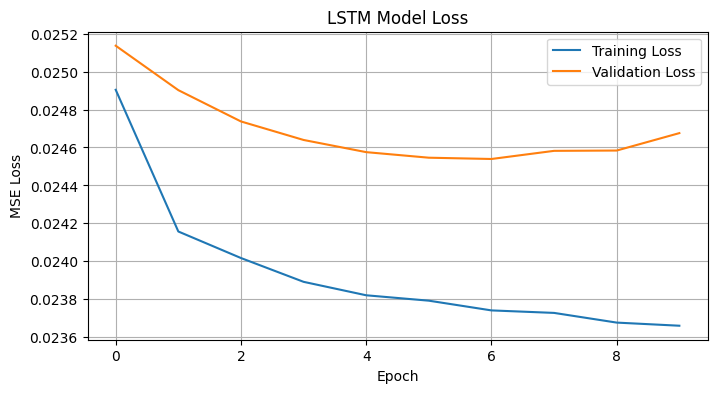

In [12]:
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Model Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
last_sequence = scaled_data[-LOOKBACK:].reshape(
    1, LOOKBACK, len(features)
)

next_scaled = model.predict(last_sequence, verbose=0)
next_values = scaler.inverse_transform(next_scaled)

print("Predicted next-row feature values:")
for name, value in zip(features, next_values[0]):
    print(f"{name}: {value:.4f}")

Predicted next-row feature values:
median7: 0.3735
median14: 0.3674
median21: 0.3665
median28: 0.3650
median35: 0.3666
